# A. Linear Scaling (Bounding the Range)
1. **Min-Max Scaling**: $X_{new} = \frac{X - X_{min}}{X_{max} - X_{min}}$. Bounds output to $[0, 1]$.
2. **Mean Normalisation**: $X_{new} = \frac{X - \mu}{X_{max} - X_{min}}$. Centers at 0.
3. **Maximum Absolute Scaling**: $X_{new} = \frac{X}{\max(|X|)}$. Preserves sparsity.
4. **Decimal Scaling**: $X_{new} = \frac{X}{10^j}$ where $j$ is the smallest integer such that $\max(|X_{new}|) < 1$.
5. **Robust Scaling (IQR)**: $X_{new} = \frac{X - Q_2}{Q_3 - Q_1}$. Uses median and interquartile range.

In [1]:
# Core dependencies
import math 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Linear scaling methods
class MinMaxScaling:
    """bounds output to 0,1"""
    def __init__(self, feature_range=(0, 1)):
        self.feature_range = feature_range
        self.data_min_ = None
        self.data_max_ = None

    def fit(self, X):
        self.data_min_ = np.min(X)
        self.data_max_ = np.max(X)

    def transform(self, X):
        if self.data_min_ is None or self.data_max_ is None:
            raise ValueError("The scaler has not been fitted yet.")
        
        scale = (self.feature_range[1] - self.feature_range[0]) / (self.data_max_ - self.data_min_)
        return self.feature_range[0] + (X - self.data_min_) * scale

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    

class MeanNormalization:
    def __init__(self):
        self.mean_ = None
        self.data_min_ = None
        self.data_max_ = None

    def fit(self, X):
        self.mean_ = np.mean(X)
        self.data_min_ = np.min(X)
        self.data_max_ = np.max(X)

    def transform(self, X):
        if self.mean_ is None:
            raise ValueError("The normalizer has not been fitted yet.")
        if self.data_max_ - self.data_min_ == 0:
            return np.zeros_like(X)
        return (X - self.mean_) / (self.data_max_ - self.data_min_)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)


class MaxAbsoluteScaling:
    def __init__(self):
        self.max_abs_ = None

    def fit(self, X):
        self.max_abs_ = np.max(np.abs(X))

    def transform(self, X):
        if self.max_abs_ is None:
            raise ValueError("The scaler has not been fitted yet.")
        if self.max_abs_ == 0:
            return np.zeros_like(X)
        return X / self.max_abs_

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    

class DecimalScaling:
    def __init__(self):
        self.j_ = None

    def fit(self, X):
        max_abs = np.max(np.abs(X))
        self.j_ = math.ceil(math.log10(max_abs + 1)) if max_abs != 0 else 0

    def transform(self, X):
        if self.j_ is None:
            raise ValueError("The scaler has not been fitted yet.")
        return X / (10 ** self.j_)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    

class RobustScaling:
    def __init__(self):
        self.median_ = None
        self.iqr_ = None

    def fit(self, X):

        self.median_ = np.median(X)
        q1 = np.percentile(X, 25)
        q3 = np.percentile(X, 75)
        self.iqr_ = q3 - q1

    def transform(self, X):
        if self.median_ is None or self.iqr_ is None:
            raise ValueError("The scaler has not been fitted yet.")
        if self.iqr_ == 0:
            return np.zeros_like(X)
        return (X - self.median_) / self.iqr_

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

# B. Statistical Normalisation (Centering and Variance)
6. **Z-Score Standardisation**: $X_{new} = \frac{X - \mu}{\sigma}$. Mean $0$, std $1$.
7. **Modified Z-Score**: $X_{new} = 0.6745 \cdot \frac{X - \tilde{x}}{\text{MAD}}$, where MAD is median absolute deviation.
8. **Pareto Scaling**: $X_{new} = \frac{X - \mu}{\sqrt{\sigma}}$. Scales by square root of SD.

In [3]:
# Statistical normalization methods
class ZscoreNormalization:
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        self.mean_ = np.mean(X)
        self.std_ = np.std(X)

    def transform(self, X):
        if self.mean_ is None or self.std_ is None:
            raise ValueError("The normalizer has not been fitted yet.")
        if self.std_ == 0:
            return np.zeros_like(X)
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    

class ModifiedZscoreNormalization:
    def __init__(self):
        self.median_ = None
        self.mad_ = None

    def fit(self, X):
        self.median_ = np.median(X)
        self.mad_ = np.median(np.abs(X - self.median_))

    def transform(self, X):
        if self.median_ is None or self.mad_ is None:
            raise ValueError("The normalizer has not been fitted yet.")
        if self.mad_ == 0:
            return np.zeros_like(X)
        return 0.6745 * (X - self.median_) / self.mad_

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    
class ParetoScaling:
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        self.mean_ = np.mean(X)
        self.std_ = np.std(X)

    def transform(self, X):
        if self.mean_ is None or self.std_ is None:
            raise ValueError("The normalizer has not been fitted yet.")
        if self.std_ == 0:
            return np.zeros_like(X)
        return (X - self.mean_) / np.sqrt(self.std_)
    
    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

# C. Non-Linear Transformations (Shape Changing)
9. **Log Transformation**: $X_{new} = \log(X + c)$. Choose $c$ to handle non-positive values.
10. **Reciprocal Transformation**: $X_{new} = \frac{1}{X}$. Handle division by zero.
11. **Square Root Transformation**: $X_{new} = \sqrt{X}$. Handle negative values.
12. **Box-Cox (\lambda = 0.5)**: $X_{new} = \frac{X^{\lambda} - 1}{\lambda}$. Requires $X > 0$.
13. **Yeo-Johnson (\lambda = 0.5)**: Handles negative values in power transforms.
14. **Hyperbolic Tangent**: $X_{new} = \tanh(X)$. Squashes to $[-1, 1]$.
15. **Sigmoid / Logistic**: $X_{new} = \frac{1}{1 + e^{-X}}$. Squashes to $(0, 1)$.

In [4]:
# Non-linear transformations
class LogTransformation:
    def __init__(self):
        self.c_ = 0 # constant to avoid log(0)

    def fit(self, X, c=0):
        self.c_ = c

    def transform(self, X):
        if np.any(X <= self.c_):
            raise ValueError("Log transformation is only defined for positive values.")
        return np.log(X + self.c_)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    
class ReciprocalTransformation:
    """
    To avoid division by zero error as mentioned c can be set to small value like 1e-9 or something.
    """
    def __init__(self):
        self.c_ = 0 # constant to avoid division by zero 

    def fit(self, X, c=0):
        self.c_ = c

    def transform(self, X):
        if np.any(X + self.c_ == 0):
            raise ValueError("Reciprocal transformation is only defined for non-zero values.")
        return 1 / (X + self.c_)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    
class SquareRootTransformation:
    def __init__(self):
        pass 

    def fit(self, X):
        return self

    def transform(self, X):
        if np.any(X < 0):
            raise ValueError("Square root transformation is only defined for non-negative values.")
        return np.sqrt(X)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    
class BoxCoxTransformation:
    def __init__(self):
        self.lmbda_ = 0.5 # default value for lambda

    def fit(self, X, lmbda=0.5):
        if np.any(X <= 0):
            raise ValueError("Box-Cox transformation is only defined for strictly positive values.")
        self.lmbda_ = lmbda

    def transform(self, X):
        if self.lmbda_ is None:
            raise ValueError("The transformer has not been fitted yet.")
        if self.lmbda_ == 0:
            return np.log(X)
        else:
            return (X ** self.lmbda_ - 1) / self.lmbda_

    def fit_transform(self, X, lmbda=0.5):
        self.fit(X, lmbda)
        return self.transform(X)
    

class YeoJohnsonTransformation:
    def __init__(self, lmbda=0.5):
        self.lmbda_ = lmbda

    def fit(self, X, lmbda=None):
        if lmbda is not None:
            self.lmbda_ = lmbda
        return self

    def transform(self, X):
        if self.lmbda_ is None:
            raise ValueError("Transformer not fitted")

        X = np.asarray(X)
        out = np.zeros_like(X, dtype=float)

        pos = X >= 0
        neg = ~pos

        if self.lmbda_ == 0:
            out[pos] = np.log(X[pos] + 1)
        else:
            out[pos] = ((X[pos] + 1) ** self.lmbda_ - 1) / self.lmbda_

        if self.lmbda_ == 2:
            out[neg] = -np.log(-X[neg] + 1)
        else:
            out[neg] = -(((-X[neg] + 1) ** (2 - self.lmbda_)) - 1) / (2 - self.lmbda_)

        return out

    def fit_transform(self, X, lmbda=None):
        return self.fit(X, lmbda).transform(X)
    
class HyperbolicTangentTransformation:
    def __init__(self):
        pass

    def fit(self, X):
        return self

    def transform(self, X):
        return np.tanh(X)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    
class LogisticTransformation:
    def __init__(self):
        pass

    def fit(self, X):
        return self

    def transform(self, X):
        return 1 / (1 + np.exp(-X))

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

# D. Vector Normalisation (Row-wise)
16. **L1 Normalisation**: $X_{new} = \frac{X}{\lVert X \rVert_1}$. Row sums to 1 in absolute value.
17. **L2 Normalisation**: $X_{new} = \frac{X}{\lVert X \rVert_2}$. Unit vector scaling.
18. **Softmax Scaling**: $X_{new,i} = \frac{e^{X_i}}{\sum_j e^{X_j}}$. Converts vector to a probability distribution.

In [5]:
# Vector normalization methods
class L1Norm:
    def __init__(self):
        pass

    def fit(self, X):
        return self
    

    def transform(self, X):
        norm = np.sum(np.abs(X))
        if norm == 0:
            return np.zeros_like(X)
        return X / norm

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    
class L2Norm:
    def __init__(self):
        pass

    def fit(self, X):
        return self

    def transform(self, X):
        norm = np.sqrt(np.sum(X ** 2))
        if norm == 0:
            return np.zeros_like(X)
        return X / norm

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    

class SoftmaxScaling:
    def __init__(self):
        pass

    def fit(self, X):
        X = np.asarray(X)
        return self

    def transform(self, X):
        X = np.asarray(X)
        
        shift_X = X - np.max(X)
        
        exp_X = np.exp(shift_X)
        softmax = exp_X / np.sum(exp_X)
        
        return softmax

    def fit_transform(self, X):
        return self.fit(X).transform(X)

# E. Distribution Mapping
19. **Quantile Normalisation (Uniform)**: Maps data ranks to a uniform distribution on $[0, 1]$.
20. **Rank-Gauss**: Maps ranks to a Gaussian distribution via the inverse CDF.

In [6]:
# Distribution mapping methods
class QuantileNormalization:
    def __init__(self, n_quantiles=100):
        self.n_quantiles = n_quantiles
        self.quantiles_ = None
        self.references_ = None

    def fit(self, X):
        X = np.asarray(X)

        self.quantiles_ = np.percentile(
            X, np.linspace(0, 100, self.n_quantiles)
        )

        self.references_ = np.linspace(0, 1, self.n_quantiles)

    def transform(self, X):
        if self.quantiles_ is None:
            raise ValueError("Call fit first")

        X = np.asarray(X)

        return np.interp(X, self.quantiles_, self.references_)

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    

class RankGaussNormalization:
    def __init__(self, n_quantiles=100):
        self.n_quantiles = n_quantiles
        self.quantiles_ = None
        self.references_ = None

    def fit(self, X):
        X = np.asarray(X)

        self.quantiles_ = np.percentile(
            X, np.linspace(0, 100, self.n_quantiles)
        )
        eps = 1e-7
        self.references_ = np.linspace(eps, 1 - eps, self.n_quantiles)

    def _erfinv(self, y):
        a = 0.147
        sign = np.sign(y)
        ln = np.log(1 - y**2)

        first = 2/(math.pi * a) + ln/2
        second = ln/a

        return sign * np.sqrt(np.sqrt(first**2 - second) - first)

    def _norm_ppf(self, p):
        return np.sqrt(2) * self._erfinv(2*p - 1)

    def transform(self, X):
        if self.quantiles_ is None:
            raise ValueError("Call fit first")

        X = np.asarray(X)

        uniform = np.interp(X, self.quantiles_, self.references_)

        gaussian = self._norm_ppf(uniform)

        return gaussian

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)
    
# i have taken help of gpt for this last distribution transformation, rest all are implemented by me. i have understood it now. 

In [ ]:
# Download dataset from API into JSONL
import urllib.request
import json
ROLL_NUMBER = 2025701040

for i in range(10000):  
    INDEX = i
    url = f"http://preon.iiit.ac.in:8026/api/data?roll={ROLL_NUMBER}&index={INDEX}"
    try:
        with urllib.request.urlopen(url) as response:
            if response.status == 200:
                data = json.loads(response.read().decode())

                print(f"Features: {data['features']}")
                print(f"Label: {data['label']}")
                with open('dataset.json', 'a') as f:
                    f.write(json.dumps(data) + '\n')
    except urllib.error.HTTPError as e:
        if e.code == 404:
            print("End of dataset reached. Stop collecting.")
            break
        else:
            print(f"An HTTP error occurred: {e.code}")

In [8]:
dataset = pd.read_json('dataset.json', lines=True)
dataset

,roll,index,features,label
0,2025701040,0,"[1.442314693770793, 7.144374835963619, 3.63936...",0
1,2025701040,1,"[22.71704929617661, 22.83002795011122, 8.35492...",1
2,2025701040,2,"[0.699387023845017, 3.950427855318255, 14.8869...",0
3,2025701040,3,"[60.272683831761825, 159.84915720099562, 8.070...",1
4,2025701040,4,"[10.981090631672586, 15.456586843717423, 111.0...",1
...,...,...,...,...
1996,2025701040,1996,"[2.3270333257435523, 0.6476945990681541, 1.710...",0
1997,2025701040,1997,"[9.907356423988084, 3.228012276338029, 1.54322...",0
1998,2025701040,1998,"[2.3385273607073582, 3.402183835995687, 1.5875...",0
1999,2025701040,1999,"[2.359380743381411, 3.035945006792189, 11.8843...",0


In [9]:
dataset['features'] = dataset['features'].apply(lambda x: np.array(x))
SCENARIO_ID = ROLL_NUMBER% 8 
SCENARIO_ID

0

In [10]:
# Train/test split (80/20)
seed  = 2025701040
np.random.seed(seed)

indices = np.random.permutation(len(dataset))
train_size = int(0.8 * len(dataset))
train_indices = indices[:train_size]
test_indices = indices[train_size:]
x_train = np.stack(dataset['features'].iloc[train_indices])
y_train = dataset['label'].iloc[train_indices].values
x_test = np.stack(dataset['features'].iloc[test_indices])
y_test = dataset['label'].iloc[test_indices].values


In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=3,metric='euclidean')
knn.fit(x_train, y_train)
y_pred = knn.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9776


In [12]:
knn = KNeighborsClassifier(n_neighbors=5,metric='euclidean')
knn.fit(x_train, y_train)
y_pred = knn.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9825


In [13]:
knn = KNeighborsClassifier(n_neighbors=1,metric='euclidean')
knn.fit(x_train, y_train)
y_pred = knn.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9875


In [14]:
knn = KNeighborsClassifier(n_neighbors=10,metric='euclidean')
knn.fit(x_train, y_train)
y_pred = knn.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9776


## 2.3.5 Final Evaluation [1 mark]
Using the optimal $k$ selected from cross-validation, each method is retrained on the full training set and evaluated on the held-out test set.
Reported metrics:
- **Test Accuracy**
- **Macro F1-Score**
These values are listed in the master results table below.

In [15]:
mean = np.mean(x_train, axis=0)
std = np.std(x_train, axis=0)
min = np.min(x_train, axis=0)
max = np.max(x_train, axis=0)
quantiles = np.percentile(x_train, [25, 50, 75], axis=0)
print("Mean:", mean)
print("Standard Deviation:", std)
print("Min:", min)
print("Max:", max)
print("Quantiles (25th, 50th, 75th):", quantiles)

Mean: [19.24562545 17.54991257 19.51936908 17.49126467 18.4835133 ]
Standard Deviation: [41.38497496 31.60590806 34.1740437  30.7708167  31.67066877]
Min: [0.14286944 0.08730689 0.03619444 0.12709247 0.05635146]
Max: [1012.92609396  590.36883898  414.56551687  446.35463834  418.14829238]
Quantiles (25th, 50th, 75th): [[ 2.59098114  2.57058776  2.62997424  2.50091387  2.49166946]
 [ 7.26707811  6.88989417  6.98859795  7.15162667  6.98493632]
 [20.50023169 19.10868698 21.67237926 19.87242914 20.56808485]]


In [16]:
# Assemble normalization methods for evaluation
class Identity:
    """No transformation, returns input as is. this is for raw baseline"""
    def fit(self, X): return self
    def transform(self, X): return X
    def fit_transform(self, X): return X

norm_methods = [
    Identity(),
    MinMaxScaling(),
    MeanNormalization(),
    MaxAbsoluteScaling(),
    DecimalScaling(),
    RobustScaling(),
    ZscoreNormalization(),
    ModifiedZscoreNormalization(),
    ParetoScaling(),    
    LogTransformation(),
    ReciprocalTransformation(),
    SquareRootTransformation(),
    BoxCoxTransformation(),
    YeoJohnsonTransformation(),
    HyperbolicTangentTransformation(),
    LogisticTransformation(),
    L1Norm(),
    L2Norm(),
    SoftmaxScaling(),
    QuantileNormalization(),
    RankGaussNormalization()
 ]
len(norm_methods)

21

In [17]:
from sklearn.metrics import accuracy_score, f1_score 
from sklearn.model_selection import KFold

In [18]:
# Evaluate each normalization method with fixed k
results = []  
for method in norm_methods:

    x_train_norm = np.array([method.fit_transform(x) for x in x_train])
    x_test_norm = np.array([method.transform(x) for x in x_test])
    
    knn = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
    knn.fit(x_train_norm, y_train)
    y_pred = knn.predict(x_test_norm)
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    print(f"{method.__class__.__name__} Accuracy: {accuracy:.4f}, F1 Score: {f1:.4f}")

    results.append({
        'Method': method.__class__.__name__,
        'Test Accuracy': accuracy,
        'MacroF1 Score': f1
    })



Identity Accuracy: 0.9776, F1 Score: 0.9776
MinMaxScaling Accuracy: 0.5611, F1 Score: 0.5544
MeanNormalization Accuracy: 0.5037, F1 Score: 0.5036
MaxAbsoluteScaling Accuracy: 0.5037, F1 Score: 0.5037
DecimalScaling Accuracy: 0.5910, F1 Score: 0.5708
RobustScaling Accuracy: 0.5910, F1 Score: 0.5875
ZscoreNormalization Accuracy: 0.4813, F1 Score: 0.4806
ModifiedZscoreNormalization Accuracy: 0.5037, F1 Score: 0.4965
ParetoScaling Accuracy: 0.6085, F1 Score: 0.5365
LogTransformation Accuracy: 0.9850, F1 Score: 0.9850
ReciprocalTransformation Accuracy: 0.9751, F1 Score: 0.9751
SquareRootTransformation Accuracy: 0.9825, F1 Score: 0.9825
BoxCoxTransformation Accuracy: 0.9825, F1 Score: 0.9825
YeoJohnsonTransformation Accuracy: 0.9825, F1 Score: 0.9825
HyperbolicTangentTransformation Accuracy: 0.9327, F1 Score: 0.9327
LogisticTransformation Accuracy: 0.9551, F1 Score: 0.9551
L1Norm Accuracy: 0.4813, F1 Score: 0.4813
L2Norm Accuracy: 0.4713, F1 Score: 0.4712
SoftmaxScaling Accuracy: 0.7905, F1 

In [19]:
# Cross-validate k for each method
results = []

k_values = list(range(1, 31))
kf = KFold(n_splits=5, shuffle=True, random_state=seed)
cv_results = {}
for method in norm_methods:
    method_name = method.__class__.__name__
    cv_scores = []

    for k in k_values:
        fold_scores = []

        for train_idx, val_idx in kf.split(x_train):
            X_tr, X_val = x_train[train_idx], x_train[val_idx]
            y_tr, y_val = y_train[train_idx], y_train[val_idx]

            # Fit ONLY on train fold
            X_tr = method.fit_transform(X_tr)
            X_val = method.transform(X_val)

            knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
            knn.fit(X_tr, y_tr)

            y_val_pred = knn.predict(X_val)
            acc = accuracy_score(y_val, y_val_pred)
            fold_scores.append(acc)

        cv_scores.append(np.mean(fold_scores))
    cv_results[method_name] = cv_scores   

    best_k = k_values[np.argmax(cv_scores)]
    best_cv_score = np.max(cv_scores)


    X_train_full = method.fit_transform(x_train)   
    X_test_full = method.transform(x_test)        

    knn = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
    knn.fit(X_train_full, y_train)

    y_pred = knn.predict(X_test_full)

    test_acc = accuracy_score(y_test, y_pred)
    test_f1 = f1_score(y_test, y_pred, average='macro')

    results.append({
        "method": method_name,
        "best_k": best_k,
        "cv_accuracy": best_cv_score,
        "test_accuracy": test_acc,
        "macro_f1": test_f1
    })


df = pd.DataFrame(results)

df["rank"] = df["test_accuracy"].rank(ascending=False, method="dense").astype(int)

df = df.sort_values(by="rank")

## 2.4 Deliverables and Analysis [12 marks]

### 2.4.1 Master Results Table [4 marks]
The table reports one row per method with the required columns:
- Method Name
- Best $k$
- Test Accuracy
- Macro F1-Score
- Rank (by test accuracy)
This follows the Appendix C template requirement.

In [20]:
df

,method,best_k,cv_accuracy,test_accuracy,macro_f1,rank
12,BoxCoxTransformation,19,0.989375,0.982544,0.982544,1
13,YeoJohnsonTransformation,19,0.988750,0.982544,0.982544,1
11,SquareRootTransformation,19,0.989375,0.982544,0.982544,1
19,QuantileNormalization,26,0.989375,0.982544,0.982543,1
20,RankGaussNormalization,16,0.989375,0.982544,0.982543,1
9,LogTransformation,7,0.989375,0.980050,0.980049,2
0,Identity,27,0.980625,0.977556,0.977556,3
1,MinMaxScaling,27,0.980625,0.977556,0.977556,3
7,ModifiedZscoreNormalization,27,0.980625,0.977556,0.977556,3
6,ZscoreNormalization,27,0.980625,0.977556,0.977556,3


In [21]:
best_row = df.sort_values("test_accuracy", ascending=False).iloc[0]
worst_row = df.sort_values("test_accuracy", ascending=True).iloc[0]

best_method_name = best_row["method"]
worst_method_name = worst_row["method"]

print("Best method:", best_method_name)
print("Best k:", best_row["best_k"])
print("Test Accuracy:", round(best_row["test_accuracy"], 4))
print("Macro F1-score:", round(best_row["macro_f1"], 4))

print("Worst method:", worst_method_name)

Best method: BoxCoxTransformation
Best k: 19
Test Accuracy: 0.9825
Macro F1-score: 0.9825
Worst method: SoftmaxScaling


### Final Evaluation Summary (Best Method)
The best method is selected by highest test accuracy from the master results table.
Its corresponding **best $k$**, **test accuracy**, and **macro F1-score** are reported from the same row.

In [22]:
feature_idx = 0 

raw_feature = x_train[:, feature_idx]
raw_feature

array([12.6814112 ,  2.52616959,  7.31956579, ...,  1.65325626,
        6.60800044,  1.12537368], shape=(1600,))

In [23]:
bx = BoxCoxTransformation()
sft = SoftmaxScaling()
best_feature = bx.fit_transform(x_train)[:, feature_idx]
worst_feature = sft.fit_transform(x_train)[:, feature_idx]

### 2.4.2 Visual Analysis [4 marks]
#### V.1 Feature Distribution Plot [2 marks]
One feature is selected and visualized across:
- (a) Raw Data
- (b) Top-performing method
- (c) Worst-performing method
Each subplot is annotated with method names.

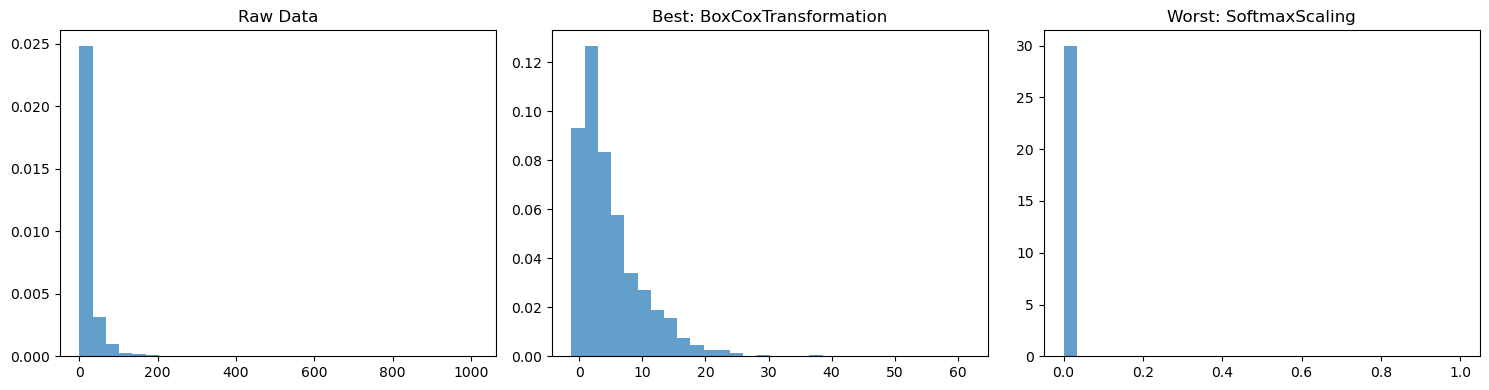

In [24]:
plt.figure(figsize=(15, 4))

# --- Raw ---
plt.subplot(1, 3, 1)
plt.hist(raw_feature, bins=30, density=True, alpha=0.7)
plt.title("Raw Data")

# --- Best ---
plt.subplot(1, 3, 2)
plt.hist(best_feature, bins=30, density=True, alpha=0.7)
plt.title(f"Best: {best_method_name}")

# --- Worst ---
plt.subplot(1, 3, 3)
plt.hist(worst_feature, bins=30, density=True, alpha=0.7)
plt.title(f"Worst: {worst_method_name}")

plt.tight_layout()
plt.show()

#### V.2 Accuracy vs. $k$ Plot [2 marks]
A line plot with:
- x-axis: $k$
- y-axis: cross-validation accuracy
Three curves are shown:
- Raw Data
- Best Method
- Worst Method

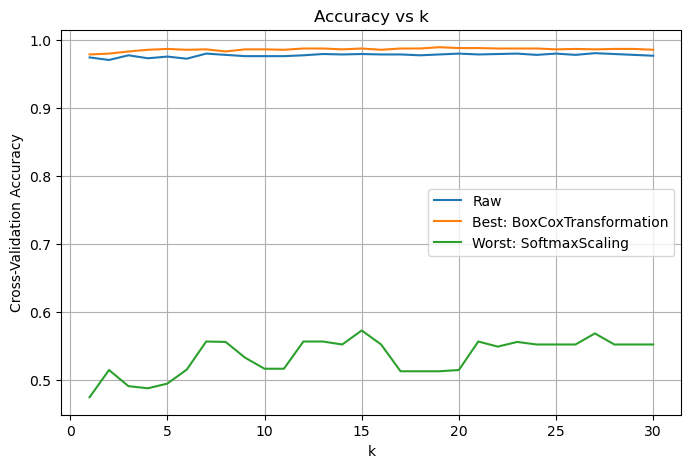

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, cv_results["Identity"], label="Raw")


plt.plot(k_values, cv_results[best_method_name], label=f"Best: {best_method_name}")


plt.plot(k_values, cv_results[worst_method_name], label=f"Worst: {worst_method_name}")

plt.xlabel("k")
plt.ylabel("Cross-Validation Accuracy")
plt.title("Accuracy vs k")
plt.legend()
plt.grid()

plt.show()